# S&P 500 Market Crash in 2020 — EDA Results and Interpretations

**Source:** `sp500_historical_data.csv` supplied for the RGBFS project. **Frequency:** weekly observations. **Unit of analysis:** S&P 500 index (`^GSPC`), not its individual constituent stocks.

This is an **executed notebook**: statistical results and figures were computed using the uploaded dataset. Markdown interpretations accompany each step. Run the notebook again to reproduce the results. The CSV must be in the same directory as this notebook (or adjust `DATA_FILE`).

## 1. Load and validate the data

**Purpose:** Handle the two metadata rows in the Yahoo Finance CSV, parse dates, and verify that prices are numeric and chronologically ordered.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path('sp500_historical_data.csv')
if not DATA_FILE.exists():
    raise FileNotFoundError(f'Place {DATA_FILE.name} next to this notebook. Current folder: {Path.cwd()}')
df = pd.read_csv(DATA_FILE, skiprows=[1, 2]).rename(columns={'Price': 'Date'})
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
for col in ['Close','High','Low','Open','Volume']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=['Date']).set_index('Date').sort_index()
print('Rows:', len(df), '| First:', df.index.min().date(), '| Last:', df.index.max().date())
print('2020 observations:', len(df.loc['2020']))
print('Missing numeric values:\n', df[['Close','High','Low','Open','Volume']].isna().sum().to_string())
print('Duplicate dates:', df.index.duplicated().sum())
print('Typical gap (days):', df.index.to_series().diff().dt.days.median())
display(df.loc['2020'].head())

Rows: 5155 | First: 1927-12-26 | Last: 2026-10-12
2020 observations: 52
Missing numeric values:
 Close     0
High      0
Low       0
Open      0
Volume    0
Duplicate dates: 0
Typical gap (days): 7.0


,Close,High,Low,Open,Volume
Date,,,,,
2020-01-06,3265.350098,3282.989990,3214.639893,3217.550049,17721020000
2020-01-13,3329.620117,3329.879883,3268.429932,3271.129883,18135300000
2020-01-20,3295.469971,3337.770020,3281.530029,3321.030029,15204110000
2020-01-27,3225.520020,3293.469971,3214.679932,3247.159912,19282920000
2020-02-03,3327.709961,3347.959961,3235.659912,3235.659912,19500010000


**Interpretation — Data quality.** The uploaded CSV contains 5,155 observations from December 26, 1927, to October 12, 2026, including **52 observations in 2020**. No numeric values are missing in the supplied data, and the typical interval is seven days. Therefore, this is a **weekly index series**, not daily prices. The `Volume` column is included, but historical index volume is not necessarily comparable across the entire century. The data is adequate for descriptive weekly index analysis; it cannot identify movements of individual S&P 500 stocks.

## 2. 2020 closing-price trend

**Purpose:** Describe the observed change between the first and last weekly closing observations in 2020 and visualize the market crash and recovery.

First weekly close: 3,265.35 (2020-01-06)
Last weekly close:  3,756.07 (2020-12-28)
First-to-last observed change: +15.03%


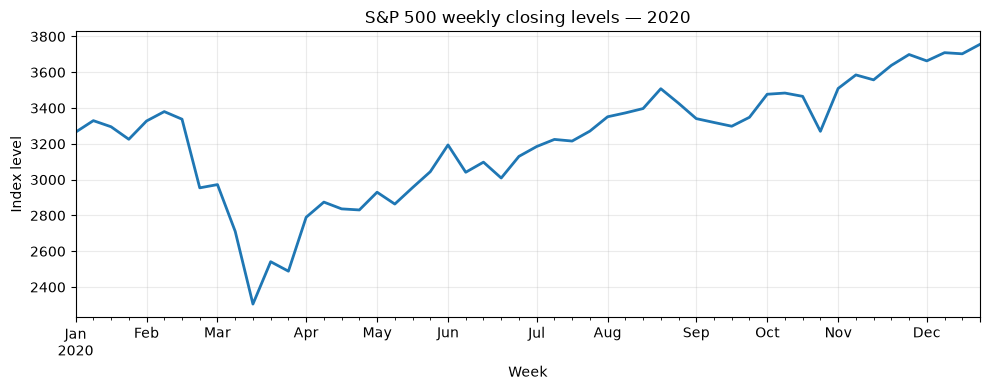

In [2]:
price = df['Close']
p2020 = price.loc['2020']
first, last = p2020.iloc[0], p2020.iloc[-1]
change = (last / first - 1) * 100
print(f'First weekly close: {first:,.2f} ({p2020.index[0].date()})')
print(f'Last weekly close:  {last:,.2f} ({p2020.index[-1].date()})')
print(f'First-to-last observed change: {change:+.2f}%')
fig, ax = plt.subplots(figsize=(10,4))
p2020.plot(ax=ax, linewidth=2)
ax.set(title='S&P 500 weekly closing levels — 2020', xlabel='Week', ylabel='Index level')
ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

**Interpretation — Performance.** The S&P 500 increased from **3,265.35** on January 6 to **3,756.07** on December 28, 2020, a **15.03%** first-to-last observed gain. This is a price-index change between the first and last available weekly observations, **not** a dividend-inclusive total return or an exact calendar-year return. The positive result conceals a severe intra-year crash: a year-end gain alone is not an adequate description of risk.

## 3. Crash depth and recovery

**Purpose:** Calculate the pre-trough weekly closing peak, the trough, maximum drawdown, and the first weekly close back above that peak.

Pre-trough weekly closing peak: 3,380.16 (2020-02-10)
Weekly closing trough: 2,304.92 (2020-03-16)
Observed peak-to-trough decline: -31.81%
First weekly close at/above peak: 2020-08-17


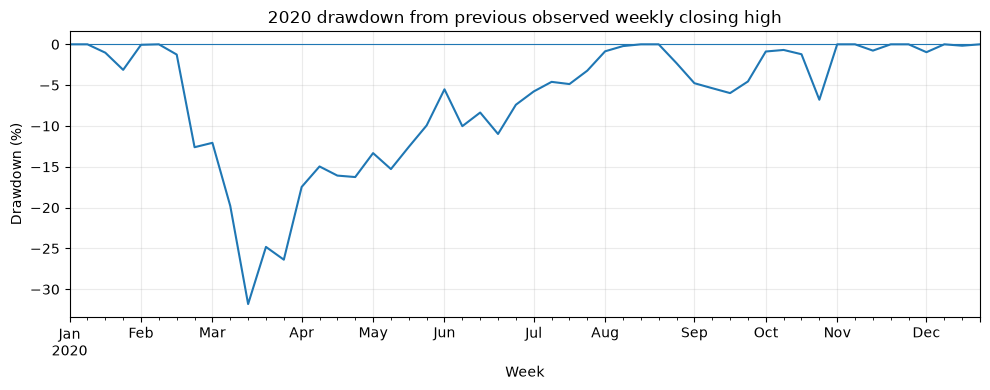

In [3]:
trough_date = p2020.idxmin()
peak_date = p2020.loc[:trough_date].idxmax()
peak, trough = p2020.loc[peak_date], p2020.loc[trough_date]
crash_dd = (trough / peak - 1) * 100
recoveries = p2020.loc[trough_date:][p2020.loc[trough_date:] >= peak]
recovery_date = recoveries.index[0] if len(recoveries) else None
running_peak = p2020.cummax()
drawdown = (p2020 / running_peak - 1) * 100
print(f'Pre-trough weekly closing peak: {peak:,.2f} ({peak_date.date()})')
print(f'Weekly closing trough: {trough:,.2f} ({trough_date.date()})')
print(f'Observed peak-to-trough decline: {crash_dd:.2f}%')
print('First weekly close at/above peak:', recovery_date.date() if recovery_date is not None else 'Not observed')
fig, ax = plt.subplots(figsize=(10,4))
drawdown.plot(ax=ax)
ax.axhline(0,linewidth=.8)
ax.set(title='2020 drawdown from previous observed weekly closing high',ylabel='Drawdown (%)',xlabel='Week')
ax.grid(alpha=.25); plt.tight_layout(); plt.show()

**Interpretation — Crash and recovery.** The pre-crash weekly closing peak was **3,380.16** on February 10, 2020. The trough was **2,304.92** on March 16, a **31.81%** decline. In a hypothetical index-tracking investment, $10,000 at the observed peak would have fallen to about **$6,819**, ignoring fees and dividends. The first observed weekly close above that peak was **August 17, 2020**. These dates refer to sampled weekly closing observations, not necessarily the exact intraday market high or low. The rebound does not imply that all constituent stocks recovered equally.

## 4. Weekly returns

**Purpose:** Quantify week-to-week gains and losses. A weekly return is `Close_t / Close_(t-1) - 1`. The first 2020 return compares with the final 2019 observation.

2020 weekly return observations: 52
Worst: -14.98% (2020-03-16)
Best:  +12.10% (2020-04-06)
Mean weekly return: +0.38%


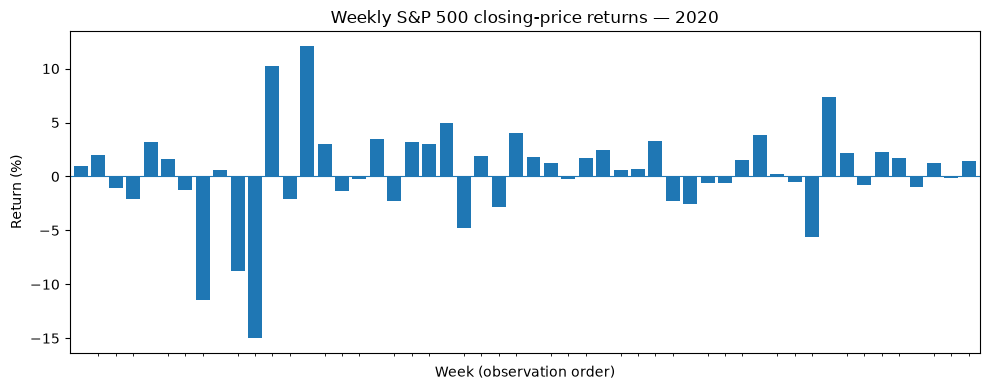

In [4]:
weekly_returns = price.pct_change(fill_method=None)
r2020 = weekly_returns.loc['2020'].dropna()
print('2020 weekly return observations:', len(r2020))
print(f'Worst: {r2020.min()*100:+.2f}% ({r2020.idxmin().date()})')
print(f'Best:  {r2020.max()*100:+.2f}% ({r2020.idxmax().date()})')
print(f'Mean weekly return: {r2020.mean()*100:+.2f}%')
fig,ax=plt.subplots(figsize=(10,4))
(r2020*100).plot(kind='bar',ax=ax,width=.8)
ax.set(title='Weekly S&P 500 closing-price returns — 2020',ylabel='Return (%)',xlabel='Week (observation order)')
ax.set_xticks([]); ax.axhline(0,linewidth=.8); plt.tight_layout();plt.show()

**Interpretation — Returns.** The worst weekly return was **−14.98%** (March 16), while the best was **+12.10%** (April 6). Such large opposite-direction moves demonstrate substantial short-horizon fluctuations during the crash and rebound. Weekly observations smooth over daily and intraday variation, so actual daily extremes may have been greater.

## 5. Volatility: 2019 versus 2020

**Purpose:** Compare the sample standard deviation of weekly returns, annualized by multiplying by `sqrt(52)`. Both years use returns ending in that calendar year, including the first observation's return from the prior year.

2019 annualized volatility: 10.85%
2020 annualized volatility: 31.73%
2020 / 2019 ratio: 2.93x


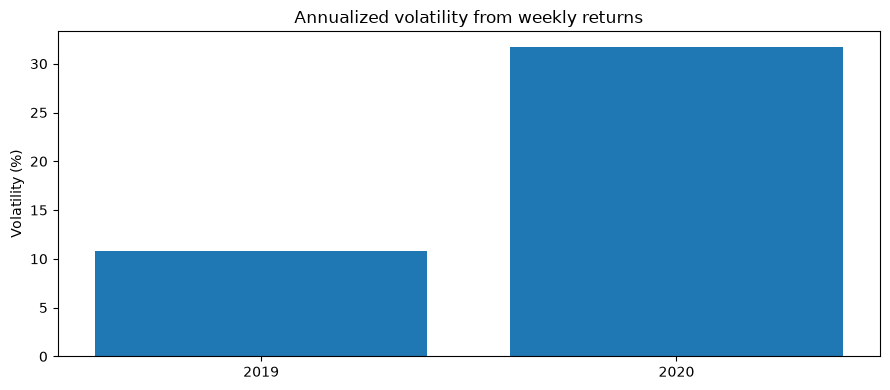

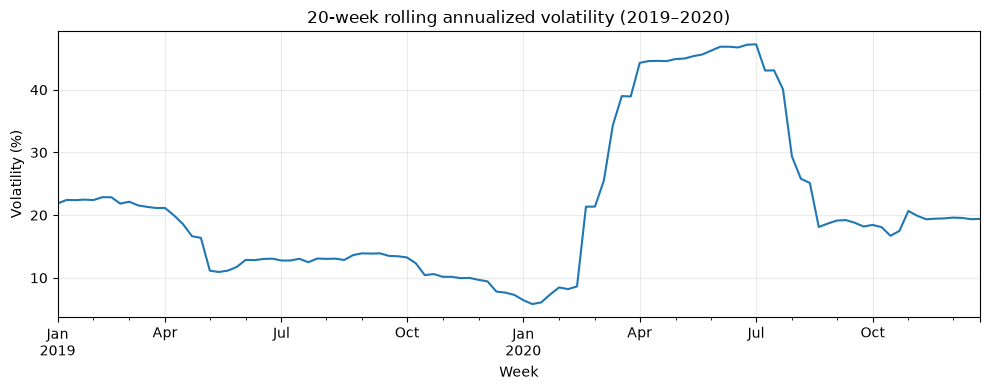

In [5]:
r2019 = weekly_returns.loc['2019'].dropna()
v2019 = r2019.std(ddof=1)*np.sqrt(52)*100
v2020 = r2020.std(ddof=1)*np.sqrt(52)*100
print(f'2019 annualized volatility: {v2019:.2f}%')
print(f'2020 annualized volatility: {v2020:.2f}%')
print(f'2020 / 2019 ratio: {v2020/v2019:.2f}x')
rolling_vol = weekly_returns.rolling(20,min_periods=20).std()*np.sqrt(52)*100
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(['2019','2020'],[v2019,v2020])
ax.set(title='Annualized volatility from weekly returns',ylabel='Volatility (%)')
plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(10,4))
rolling_vol.loc['2019':'2020'].plot(ax=ax)
ax.set(title='20-week rolling annualized volatility (2019–2020)',ylabel='Volatility (%)',xlabel='Week')
ax.grid(alpha=.25);plt.tight_layout();plt.show()

**Interpretation — Volatility.** Using the same year-ending weekly-return definition, annualized volatility was **10.85% in 2019** and **31.73% in 2020**, approximately **2.93 times higher**. This measures dispersion of weekly returns, not the probability of a particular loss. The 20-week rolling plot shows how variability evolved over time. This is a **descriptive** comparison, not a statistical significance test or proof that COVID-19 alone caused the increase.

## 6. Summary table and final interpretation

**Purpose:** Collect the main numerical findings into one reproducible table.

In [6]:
summary = pd.DataFrame({'Metric':['2020 weekly observations','First observed close','Last observed close','First-to-last change (%)','Observed pre-crash peak','Observed crash trough','Peak-to-trough drawdown (%)','Worst weekly return (%)','Best weekly return (%)','2019 annualized volatility (%)','2020 annualized volatility (%)','First recovery week'], 'Value':[len(p2020),round(first,2),round(last,2),round(change,2),round(peak,2),round(trough,2),round(crash_dd,2),round(r2020.min()*100,2),round(r2020.max()*100,2),round(v2019,2),round(v2020,2),str(recovery_date.date()) if recovery_date is not None else 'Not observed']})
display(summary)

,Metric,Value
0,2020 weekly observations,52
1,First observed close,3265.35
2,Last observed close,3756.07
3,First-to-last change (%),15.03
4,Observed pre-crash peak,3380.16
5,Observed crash trough,2304.92
6,Peak-to-trough drawdown (%),-31.81
7,Worst weekly return (%),-14.98
8,Best weekly return (%),12.1
9,2019 annualized volatility (%),10.85


### Overall research interpretation

The S&P 500 experienced a sharp market decline during the early 2020 COVID-19 period. From the observed weekly closing peak on February 10 to the trough on March 16, the index fell **31.81%**. Its worst weekly return was **−14.98%**, followed by a best weekly gain of **12.10%** in early April. Annualized weekly-return volatility increased from **10.85% in 2019** to **31.73% in 2020**, showing substantially more variable price movements. Nevertheless, the index first exceeded its pre-crash observed weekly closing peak by **August 17**, and the first-to-last observed 2020 closing-price change was **+15.03%**.

**Key lesson:** A positive end-of-period return can coexist with very large interim losses and high volatility. Evaluating returns, drawdowns, and volatility together provides a more complete picture of market risk.

**Limitations:** This is descriptive index-level EDA using weekly closing prices. It is not a causal estimate of COVID-19's effects; it does not include dividends, inflation adjustments, constituent-level correlations, stock membership, or intraday extremes. The historical source file should be validated for provenance and any later revisions before formal publication.